# 2018 — Neural Ordinary Differential Equations

**Paper:** Ricky T. Q. Chen, Yulia Rubanova, Jesse Bettencourt & David Duvenaud, *"Neural Ordinary Differential Equations"*, NeurIPS 2018 (best paper). The adjoint method itself is classical optimal control (Pontryagin et al., 1962).

A residual block computes $h_{t+1} = h_t + f(h_t)$ (notebook 29). That is one **Euler step** of the differential equation

$$\frac{dh(t)}{dt} = f\big(h(t), t, \theta\big)$$

A Neural ODE takes the limit: the network *is* $f$, and the output is $h(T)$, computed by any ODE solver. Depth becomes continuous time.

- **Constant memory training** with the **adjoint method**: instead of storing every solver step for backpropagation, solve a second ODE backwards in time for the gradient, $\frac{da}{dt} = -a^\top \frac{\partial f}{\partial h}$ with $a(t) = \partial L/\partial h(t)$, and accumulate $\frac{dL}{d\theta} = -\int_{T}^{0} a^\top \frac{\partial f}{\partial \theta}\,dt$.
- **Continuous time:** irregularly sampled observations (medical records, physics) fit naturally, and the learned dynamics can be integrated to any time.
- **Continuous normalizing flows:** the change of variables becomes $\frac{d\log p}{dt} = -\operatorname{tr}\frac{\partial f}{\partial h}$, the idea that later became flow matching (notebook 55).

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
device = torch.device("cpu")

PyTorch 2.15.0 | device: mps


## A solver and the adjoint method, from scratch
Fixed-step RK4. `odeint` backpropagates through the solver steps (memory grows with steps); `odeint_adjoint` stores nothing from the forward pass and recomputes $h(t)$ backwards together with the adjoint.

In [2]:
def rk4_step(f, h, t, dt):
    k1 = f(h, t); k2 = f(h + dt / 2 * k1, t + dt / 2); k3 = f(h + dt / 2 * k2, t + dt / 2); k4 = f(h + dt * k3, t + dt)
    return h + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def odeint(f, h0, ts, steps_per_unit=20):
    out, h = [h0], h0
    for t0, t1 in zip(ts[:-1], ts[1:]):
        n = max(1, int(math.ceil((t1 - t0) * steps_per_unit))); dt = (t1 - t0) / n
        for i in range(n): h = rk4_step(f, h, t0 + i * dt, dt)
        out.append(h)
    return torch.stack(out)

class Adjoint(torch.autograd.Function):
    @staticmethod
    def forward(ctx, h0, ts, f, steps, *params):
        with torch.no_grad(): hs = odeint(f, h0, ts.tolist(), steps)
        ctx.f, ctx.steps = f, steps; ctx.save_for_backward(ts, hs, *params)
        return hs
    @staticmethod
    def backward(ctx, g):
        ts, hs, *params = ctx.saved_tensors; f, steps = ctx.f, ctx.steps
        def aug(state, t):                                                  # dynamics of [h, a, a_θ], run backwards in time
            h, a = state[0], state[1]
            with torch.enable_grad():
                h = h.detach().requires_grad_(True)
                fh = f(h, t)
                vjp = torch.autograd.grad(fh, (h, *params), -a, allow_unused=True)
            dth = torch.cat([(v if v is not None else torch.zeros_like(p)).flatten() for v, p in zip(vjp[1:], params)])
            return [fh, vjp[0], dth]
        a, a_theta, h = g[-1], torch.zeros(sum(p.numel() for p in params)), hs[-1]
        tl = ts.tolist()
        for i in range(len(tl) - 1, 0, -1):
            t0, t1 = tl[i], tl[i - 1]                                       # integrate from t_i back to t_{i-1}
            n = max(1, int(math.ceil((t0 - t1) * steps))); dt = (t1 - t0) / n
            state = [h, a, a_theta]
            for k in range(n):
                tt = t0 + k * dt
                F_ = lambda s, t: aug(s, t)
                k1 = F_(state, tt); s2 = [x + dt / 2 * y for x, y in zip(state, k1)]
                k2 = F_(s2, tt + dt / 2); s3 = [x + dt / 2 * y for x, y in zip(state, k2)]
                k3 = F_(s3, tt + dt / 2); s4 = [x + dt * y for x, y in zip(state, k3)]
                k4 = F_(s4, tt + dt)
                state = [x + dt / 6 * (y1 + 2 * y2 + 2 * y3 + y4) for x, y1, y2, y3, y4 in zip(state, k1, k2, k3, k4)]
            h, a, a_theta = state
            a = a + g[i - 1]                                                # add the loss gradient at the observation time
        grads, off = [], 0
        for p in params: grads.append(a_theta[off:off + p.numel()].view_as(p)); off += p.numel()
        return (a, None, None, None, *grads)

def odeint_adjoint(f, h0, ts, steps=20):
    return Adjoint.apply(h0, torch.tensor(ts), f, steps, *f.parameters())

class ODEFunc(nn.Module):
    def __init__(self, d=2, h=50):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, h), nn.Tanh(), nn.Linear(h, d))
    def forward(self, h, t): return self.net(h)

### Check: the adjoint gradient equals backpropagation through the solver

In [3]:
seed_everything(0); f = ODEFunc(); h0 = torch.randn(16, 2); ts = [0.0, 0.5, 1.3, 2.0]
loss_bp = odeint(f, h0, ts).pow(2).sum(); g_bp = torch.autograd.grad(loss_bp, list(f.parameters()))
loss_adj = odeint_adjoint(f, h0, ts).pow(2).sum(); g_adj = torch.autograd.grad(loss_adj, list(f.parameters()))
for (n, _), a, b in zip(f.named_parameters(), g_bp, g_adj):
    print(f"{n:14s} max relative difference {((a - b).abs().max() / a.abs().max()).item():.2e}")

net.0.weight   max relative difference 3.65e-07
net.0.bias     max relative difference 2.76e-07
net.2.weight   max relative difference 4.27e-07
net.2.bias     max relative difference 1.95e-07


## Learning dynamics from a trajectory
The paper's toy problem: observations of the spiral $\frac{dz}{dt} = A z^3$ (element-wise cube), sampled on $t\in[0, 10]$. We train only on $t\le 6$, then use the learned ODE on $t>6$, where the spiral has moved inward to a region it never saw, to test whether it **extrapolates**.

In [4]:
A_true = torch.tensor([[-0.1, 2.0], [-2.0, -0.1]])
true_f = lambda z, t: (z ** 3) @ A_true.T
t_all = torch.linspace(0, 10, 201)
with torch.no_grad(): z_true = odeint(true_f, torch.tensor([[2.0, 0.0]]), t_all.tolist(), 40)[:, 0]
z_obs = z_true + 0.02 * torch.randn_like(z_true)
train_n = int((t_all <= 6).sum())

class CubicODE(nn.Module):
    """f(z) = MLP(z³): the same input feature the paper's toy model uses."""
    def __init__(self, h=50):
        super().__init__(); self.net = nn.Sequential(nn.Linear(2, h), nn.Tanh(), nn.Linear(h, 2))
    def forward(self, z, t): return self.net(z ** 3)

seed_everything(0); func = CubicODE(); opt = torch.optim.Adam(func.parameters(), lr=1e-2); t0 = time.time()
for it in range(400):
    s = np.random.randint(0, train_n - 20, 16)                               # 16 random windows of 20 observations
    loss = 0
    for st in s:
        ts_ = t_all[st:st + 20].tolist()
        pred = odeint_adjoint(func, z_obs[st][None], ts_, steps=10)[:, 0]
        loss = loss + (pred - z_obs[st:st + 20]).abs().mean()
    loss = loss / len(s); opt.zero_grad(); loss.backward(); opt.step()
    if it % 100 == 99: print(f"iteration {it + 1}: loss {loss.item():.4f}  ({time.time() - t0:.0f}s)")
def forecast(z0, t0_idx, h=20):
    """Integrate the learned ODE for one time unit (20 observations) from a true state."""
    with torch.no_grad(): return odeint(func, z0[None], t_all[t0_idx:t0_idx + h].tolist(), 40)[:, 0]
def forecast_error(lo, hi, h=20):
    return np.mean([(forecast(z_true[s], s, h) - z_true[s:s + h]).norm(dim=1).mean().item() for s in range(lo, hi - h, 5)])
r = z_true.norm(dim=1)
print(f"1-time-unit forecasts from true states: error {forecast_error(0, train_n):.3f} on t ≤ 6 (|z| ≈ {r[:train_n].mean():.2f}), "
      f"{forecast_error(train_n, len(t_all)):.3f} on the extrapolated t ∈ (6, 10] (|z| ≈ {r[train_n:].mean():.2f})")
with torch.no_grad(): z_fit = odeint(func, z_true[:1], t_all.tolist(), 40)[:, 0]
turns = torch.atan2(z_true[:, 1], z_true[:, 0]).diff().abs().clamp(max=3).sum().item() / (2 * math.pi)
print(f"one long rollout from t = 0: mean error {(z_fit - z_true).norm(dim=1).mean():.3f}; the true path makes {turns:.1f} turns, so small speed errors become phase drift")

iteration 100: loss 0.0895  (11s)


iteration 200: loss 0.0962  (22s)


iteration 300: loss 0.0825  (34s)


iteration 400: loss 0.0560  (46s)
1-time-unit forecasts from true states: error 0.072 on t ≤ 6 (|z| ≈ 1.32), 0.020 on the extrapolated t ∈ (6, 10] (|z| ≈ 0.85)
one long rollout from t = 0: mean error 1.356; the true path makes 4.5 turns, so small speed errors become phase drift


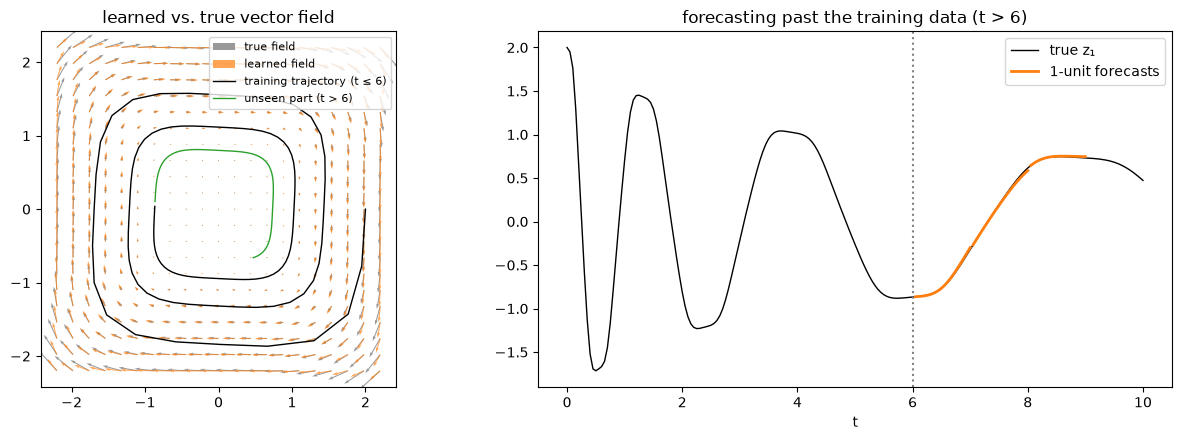

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
g = torch.linspace(-2.2, 2.2, 21); gx, gy = torch.meshgrid(g, g, indexing="xy"); grid = torch.stack([gx.flatten(), gy.flatten()], 1)
with torch.no_grad(): v_true, v_fit = true_f(grid, 0), func(grid, 0)
axes[0].quiver(grid[:, 0], grid[:, 1], v_true[:, 0], v_true[:, 1], color="0.6", label="true field")
axes[0].quiver(grid[:, 0], grid[:, 1], v_fit[:, 0], v_fit[:, 1], color="C1", alpha=0.7, label="learned field")
axes[0].plot(*z_true[:train_n].T, "k-", lw=1, label="training trajectory (t ≤ 6)"); axes[0].plot(*z_true[train_n:].T, "C2-", lw=1, label="unseen part (t > 6)")
axes[0].set(title="learned vs. true vector field"); axes[0].legend(fontsize=8); axes[0].set_aspect("equal")
axes[1].plot(t_all, z_true[:, 0], "k", lw=1, label="true z₁")
for s in range(train_n, len(t_all) - 20, 20):
    f = forecast(z_true[s], s); axes[1].plot(t_all[s:s + 20], f[:, 0], "C1", lw=2, label="1-unit forecasts" if s == train_n else None)
axes[1].axvline(6, c="gray", ls=":"); axes[1].set(xlabel="t", title="forecasting past the training data (t > 6)"); axes[1].legend()
plt.tight_layout(); plt.show()

## Takeaways
- **ResNets are Euler discretisations**; Neural ODEs replace the stack of blocks with a vector field and a solver.
- **What extrapolation means here.** Forecasts of one time unit stay accurate even on the unseen inner part of the spiral, because the learned vector field matches the true one there. A single rollout over all ten time units drifts in phase: the path makes several turns, so a small error in speed accumulates. This is the usual behaviour of learned dynamics models, and why they are re-anchored on fresh observations.
- **The adjoint method** computes exact gradients (up to solver error) by solving a second ODE backwards, with memory independent of the number of steps. The price is extra compute, and with adaptive solvers the number of function evaluations can grow during training.
- **Legacy:** continuous normalizing flows (FFJORD, 2018), latent ODEs for irregular time series, and physics-informed models. The view of generative modelling as integrating a learned velocity field became **flow matching** (notebook 55) and the probability-flow ODE of diffusion models (notebook 50), now the basis of image and video generators.